# Notebook 04 — Mediciones de laboratorio
**TP Integrador — Filtros analógicos activos · Grupo 3 · LP Chebyshev I, orden 3 (TL072CP)**

Contenido:
1. Plan de medición: frecuencias, amplitudes y valores esperados → `mediciones/plantilla_mediciones.csv` y hoja de laboratorio imprimible.
2. Lectura de `mediciones/mediciones.csv` (y `mediciones/metadatos.json`) cuando existan. **Nunca se inventan resultados**: si no hay datos medidos,
   las celdas de procesamiento lo indican y no generan figuras.
3. Ganancia y fase con incertidumbre, comparación **Python – LTspice – mediciones**.
4. Parámetros característicos: $A_{p,\max}$, frecuencia de −3 dB, $A(4\ \mathrm{kHz})$, y ajuste de $f_r$, $f_0$ y $Q$ por mínimos cuadrados.
5. Estimación indirecta de los capacitores reales a partir de los parámetros ajustados y de las resistencias medidas.
6. Retardo de grupo estimado a partir de la fase medida.

**Qué se mide.** La transferencia medida es $V_6/V_1$: la entrada se toma en el borne de entrada del filtro (nodo 1, después de la resistencia
interna del generador), de modo que $R_s$ no interviene y el modelo de comparación es $H_c$ con $R_s = 0$.

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np
import scipy
from scipy import signal, optimize
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__} | pandas {pd.__version__}")
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG, RES, LTS, MED = ROOT / 'figuras', ROOT / 'resultados', ROOT / 'ltspice', ROOT / 'mediciones'
for d_ in (FIG, RES, MED):
    d_.mkdir(exist_ok=True)

AZUL, NARANJA, VERDE, AMARILLO, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#9a9a96'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.grid': True, 'grid.color': '#d9d9d6', 'grid.linewidth': 0.6, 'axes.edgecolor': '#6b6b67',
    'axes.linewidth': 0.8, 'lines.linewidth': 1.6, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
})
def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight'); fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')
def num(x, nd=3):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '---'
    x = 0.0 if abs(x) < 0.5 * 10**(-nd) else x
    t = f'{abs(x):.{nd}f}'.replace('.', '{,}')
    return ('$-$' + t) if x < 0 else t

DATOS = json.load(open(RES / 'componentes.json', encoding='utf-8'))
COMP, PL = DATOS['componentes'], DATOS['plantilla']

def H_modelo(f, wr, w0, Q, K=1.0):
    """Transferencia V6/V1 del circuito (AO ideal): K * wr/(s+wr) * w0^2/(s^2 + w0/Q s + w0^2)."""
    sj = 2j * np.pi * np.asarray(f, float)
    return K * wr / (sj + wr) * w0**2 / (sj**2 + w0 / Q * sj + w0**2)

def parametros_de_componentes(c, Rs=0.0):
    wr = 1 / ((c['R0'] + Rs) * c['C0'])
    w0 = 1 / np.sqrt(c['R1'] * c['R2'] * c['C1'] * c['C2'])
    Q = np.sqrt(c['C1'] / c['C2']) * np.sqrt(c['R1'] * c['R2']) / (c['R1'] + c['R2'])
    return wr, w0, Q

WR_N, W0_N, Q_N = parametros_de_componentes(COMP, Rs=0.0)
print(f'Nominal (V6/V1, Rs excluida): f_r = {WR_N/2/np.pi:.2f} Hz, f_0 = {W0_N/2/np.pi:.2f} Hz, Q = {Q_N:.4f}')

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | Matplotlib 3.11.2 | pandas 3.0.5
Nominal (V6/V1, Rs excluida): f_r = 774.10 Hz, f_0 = 1201.08 Hz, Q = 1.5525


## 1. Plan de medición
**Frecuencias:** 34 puntos entre 20 Hz y 20 kHz, densos entre 700 Hz y 1,5 kHz (rizado, borde de paso y transición), que cubren la banda de paso, la
de transición y la de rechazo.

**Amplitud de entrada:** 1 V eficaz hasta 2 kHz (margen de más de 7 veces respecto de la saturación, ver notebook 02/03). Desde 2,5 kHz la salida es
muy chica, de modo que se sube la entrada al máximo práctico del generador (se propone 3 V eficaces ≈ 8,5 V pico a pico) para mejorar la relación
señal/ruido; a esas frecuencias la etapa 1 ya atenúa y ningún nodo se acerca a la saturación.

**Fase:** se mide el retardo $\Delta t$ entre los cruces por cero ascendentes de $v_1$ (canal 1, referencia) y $v_o$ (canal 2); con $\Delta t > 0$ si la
salida está atrasada, $\varphi = -360^\circ\,f\,\Delta t$. Como la fase real llega a −270°, el osciloscopio mide $\varphi$ módulo 360°; la columna
`fase_esperada_grados` permite elegir el giro correcto (el notebook lo hace automáticamente).

In [2]:
F_PLAN = [20, 50, 100, 200, 300, 400, 500, 600, 700, 800, 850, 900, 950, 1000, 1050, 1100, 1150, 1200, 1250, 1300,
          1400, 1500, 1700, 2000, 2500, 3000, 3500, 4000, 5000, 6000, 8000, 10000, 15000, 20000]
Hn = H_modelo(F_PLAN, WR_N, W0_N, Q_N)
fase_esp = np.degrees(np.unwrap(np.angle(H_modelo(np.geomspace(1, 20000, 4000), WR_N, W0_N, Q_N))))
fase_esp = np.interp(np.log(F_PLAN), np.log(np.geomspace(1, 20000, 4000)), fase_esp)
vin_sug = np.where(np.array(F_PLAN) <= 2000, 1.0, 3.0)
plan = pd.DataFrame({
    'frecuencia_Hz': F_PLAN, 'Vin_Vrms': '', 'Vout_Vrms': '', 'fase_grados': '', 'delta_t_s': '', 'notas': '',
    'Vin_sugerida_Vrms': vin_sug, 'ganancia_esperada_dB': np.round(20 * np.log10(np.abs(Hn)), 3),
    'Vout_esperada_Vrms': np.round(vin_sug * np.abs(Hn), 6), 'fase_esperada_grados': np.round(fase_esp, 2),
    'delta_t_esperado_us': np.round(-fase_esp / 360 / np.array(F_PLAN) * 1e6, 2),
})
plan.to_csv(MED / 'plantilla_mediciones.csv', index=False)
plan[['frecuencia_Hz', 'Vin_sugerida_Vrms', 'ganancia_esperada_dB', 'Vout_esperada_Vrms', 'fase_esperada_grados', 'delta_t_esperado_us']]

,frecuencia_Hz,Vin_sugerida_Vrms,ganancia_esperada_dB,Vout_esperada_Vrms,fase_esperada_grados,delta_t_esperado_us
0,20,1.0,-0.001,0.999886,-2.09,290.93
1,50,1.0,-0.006,0.999292,-5.23,290.79
2,100,1.0,-0.024,0.997229,-10.45,290.33
3,200,1.0,-0.089,0.989814,-20.78,288.63
4,300,1.0,-0.174,0.980145,-30.92,286.30
5,400,1.0,-0.252,0.971357,-40.89,283.97
6,500,1.0,-0.296,0.966529,-50.83,282.39
7,600,1.0,-0.283,0.967982,-60.99,282.35
8,700,1.0,-0.207,0.976479,-71.74,284.68
9,800,1.0,-0.089,0.989775,-83.58,290.21


**Metadatos.** `mediciones/metadatos.json` documenta las condiciones (instrumentos, alimentación, carga, temperatura) y los **valores reales medidos
de las resistencias** (con multímetro), que se usan en la comparación y en la estimación indirecta de los capacitores. Se genera una plantilla.

In [3]:
META_PLANTILLA = {
    'fecha': 'AAAA-MM-DD', 'integrantes_que_midieron': [], 'temperatura_ambiente_C': None,
    'osciloscopio': {'modelo': '', 'ancho_de_banda_MHz': None, 'precision_vertical_pct': 3.0,
                     'puntas': 'x10, 10 MΩ || ~15 pF', 'promediado': 'p. ej. 16 adquisiciones'},
    'generador': {'modelo': '', 'impedancia_salida_ohm': 50},
    'fuente': {'modelo': '', 'tension_V': [12.0, -12.0], 'limite_corriente_mA': 50},
    'multimetro': {'modelo': '', 'precision_ohm_pct': None},
    'carga_salida': 'osciloscopio (10 MΩ con punta x10)',
    'incertidumbre_fase_grados': 1.0,
    'resistencias_medidas_ohm': {'R0a': None, 'R0b': None, 'R1a': None, 'R1b': None, 'R2a': None, 'R2b': None},
    'capacitores': {'C0': '10 nF, código/tolerancia: ', 'C1': '47 nF, código/tolerancia: ', 'C2': '4,7 nF, código/tolerancia: '},
    'offset_salida_mV': None,
    'observaciones': '',
}
json.dump(META_PLANTILLA, open(MED / 'metadatos_plantilla.json', 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
print('Plantillas generadas:', [p.name for p in MED.glob('*plantilla*')])

Plantillas generadas: ['metadatos_plantilla.json', 'plantilla_mediciones.csv']


**Hoja de laboratorio imprimible** (`mediciones/hoja_laboratorio.tex`, se compila con `pdflatex`).

In [4]:
filas_hoja = []
for _, r in plan.iterrows():
    g_txt = f"{r.ganancia_esperada_dB:.2f}".replace('-0.00', '0.00')
    filas_hoja.append(f"{int(r.frecuencia_Hz)} & {r.Vin_sugerida_Vrms:.0f} & {g_txt} & {r.Vout_esperada_Vrms*1e3:.4g} & "
                      f"{r.fase_esperada_grados:.1f} & {r.delta_t_esperado_us:.1f} & & & & \\\\ \\hline")
hoja = r'''\documentclass[10pt,a4paper]{article}
\usepackage[utf8]{inputenc}\usepackage[T1]{fontenc}\usepackage{lmodern}
\usepackage[margin=1.2cm,landscape]{geometry}\usepackage{array,longtable}
\pagestyle{empty}
\begin{document}
\noindent\textbf{TP Integrador SRA 2026 -- Grupo 3 -- Hoja de medici\'on del filtro LP Chebyshev I (TL072CP)}\\[2pt]
Fecha: \rule{3cm}{0.4pt} \quad Integrantes: \rule{7cm}{0.4pt} \quad Temperatura: \rule{1.5cm}{0.4pt} $^\circ$C
\quad Alimentaci\'on medida: $+$\rule{1.2cm}{0.4pt} V \; $-$\rule{1.2cm}{0.4pt} V\\[2pt]
Osciloscopio: \rule{4cm}{0.4pt} \quad Generador: \rule{4cm}{0.4pt} \quad Fuente: \rule{3.5cm}{0.4pt} \quad Mult\'imetro: \rule{3.5cm}{0.4pt}\\[2pt]
R medidas [$\Omega$]: R0a \rule{1.4cm}{0.4pt} R0b \rule{1.4cm}{0.4pt} R1a \rule{1.4cm}{0.4pt} R1b \rule{1.4cm}{0.4pt}
R2a \rule{1.4cm}{0.4pt} R2b \rule{1.4cm}{0.4pt} \quad C (c\'odigos): C0 \rule{1.2cm}{0.4pt} C1 \rule{1.2cm}{0.4pt} C2 \rule{1.2cm}{0.4pt}\\[2pt]
\small CH1 = $v_1$ (borne de entrada, nodo 1), CH2 = $v_o$ (nodo 6). Fase: $\varphi = -360^\circ f\,\Delta t$, $\Delta t>0$ si $v_o$ atrasa. Acoplamiento DC,
promediado activado, l\'imite de ancho de banda 20 MHz.\\[4pt]
\renewcommand{\arraystretch}{1.25}
\begin{longtable}{|r|c|c|c|c|c|p{2.4cm}|p{2.4cm}|p{2.4cm}|p{3.6cm}|}
\hline
$f$ [Hz] & $V_i$ sug. [V$_{\mathrm{rms}}$] & $G$ esp. [dB] & $V_o$ esp. [mV$_{\mathrm{rms}}$] & $\varphi$ esp. [$^\circ$] & $\Delta t$ esp. [$\mu$s] &
$V_i$ medido & $V_o$ medido & $\Delta t$ medido & Notas (escalas, ruido) \\ \hline
\endhead
''' + '\n'.join(filas_hoja) + r'''
\end{longtable}
\end{document}
'''
(MED / 'hoja_laboratorio.tex').write_text(hoja, encoding='utf-8')
print('Hoja de laboratorio:', MED / 'hoja_laboratorio.tex')

Hoja de laboratorio: /home/claude/Filtros_SRA_2026/mediciones/hoja_laboratorio.tex


## 2. Lectura de las mediciones
Se aceptan dos formatos (se usa el primero que exista):
1. `mediciones/mediciones.csv` — medición manual punto a punto: `frecuencia_Hz`, `Vin_Vrms`, `Vout_Vrms`, `fase_grados` (o `delta_t_s`).
2. `mediciones/nivel3/bode_filtro.csv` — exportación **sin modificar** del modo *Bode* del osciloscopio Rigol (`Freq(Hz)`, `Gain(dB)`, `Phase`), que barre
   la frecuencia con el generador interno y mide ganancia y fase entre el canal de entrada y el de salida.

In [5]:
META = json.load(open(MED / 'metadatos.json', encoding='utf-8')) if (MED / 'metadatos.json').exists() else META_PLANTILLA
HAY_DATOS, FUENTE = False, None
MED3 = MED / 'nivel3'
if (MED / 'mediciones.csv').exists():
    datos = pd.read_csv(MED / 'mediciones.csv')
    for c_ in ('Vin_Vrms', 'Vout_Vrms', 'fase_grados', 'delta_t_s'):
        if c_ in datos:
            datos[c_] = pd.to_numeric(datos[c_].astype(str).str.replace(',', '.'), errors='coerce')
    datos = datos.dropna(subset=['Vin_Vrms', 'Vout_Vrms']).sort_values('frecuencia_Hz').reset_index(drop=True)
    if 'fase_grados' not in datos or datos['fase_grados'].isna().all():
        datos['fase_grados'] = -360 * datos['frecuencia_Hz'] * datos.get('delta_t_s', np.nan)
    f_m = datos['frecuencia_Hz'].to_numpy(float)
    G_m = 20 * np.log10(datos['Vout_Vrms'] / datos['Vin_Vrms']).to_numpy()
    F_raw = datos['fase_grados'].to_numpy(float)
    FUENTE, HAY_DATOS = 'medición manual (mediciones.csv)', len(datos) > 0
elif (MED / 'nivel3' / 'bode_filtro.csv').exists():
    ARCH_BODE = MED / 'nivel3' / 'bode_filtro.csv'
    lineas_rigol = ARCH_BODE.read_text(encoding='utf-8', errors='ignore').splitlines()
    i0 = next(i for i, l in enumerate(lineas_rigol) if l.lower().startswith('freq'))
    datos = pd.read_csv(ARCH_BODE, skiprows=i0)
    datos.columns = ['frecuencia_Hz', 'ganancia_dB', 'fase_grados'] + list(datos.columns[3:])
    datos = datos.dropna(subset=['frecuencia_Hz', 'ganancia_dB']).sort_values('frecuencia_Hz').reset_index(drop=True)
    f_m = datos['frecuencia_Hz'].to_numpy(float)
    G_m = datos['ganancia_dB'].to_numpy(float)
    F_raw = datos['fase_grados'].to_numpy(float)
    cab = {l.split(':')[0].strip(): l.split(',')[-1].strip() for l in lineas_rigol[:i0] if ':' in l}
    FUENTE, HAY_DATOS = f"modo Bode Rigol, puntas ×10 (nivel3/bode_filtro.csv, {cab.get('StartFreq', '?')} Hz – {cab.get('StopFreq', '?')} Hz)", len(datos) > 0
MED3 = MED / 'nivel3'
def leer_rigol(p):
    lin = p.read_text(encoding='utf-8', errors='ignore').splitlines()
    i0 = next(i for i, l in enumerate(lin) if l.lower().startswith('freq'))
    d = pd.read_csv(p, skiprows=i0); d.columns = ['f', 'G', 'F'] + list(d.columns[3:])
    d = d.dropna(subset=['f', 'G']).sort_values('f').reset_index(drop=True)
    return d['f'].to_numpy(float), d['G'].to_numpy(float), d['F'].to_numpy(float)
def sin_arranque(f, G, F, n_max=5, tol_dB=0.3):
    ref = np.median(G[n_max:n_max + 8]); i = 0
    while i < n_max and abs(G[i] - ref) > tol_dB:
        i += 1
    return f[i:], G[i:], F[i:]
SEGUNDA = HAY_DATOS and not (MED / 'mediciones.csv').exists()     # medición con el modo Bode (puntas ×10)
if SEGUNDA:
    f_m, G_m, F_raw = sin_arranque(f_m, G_m, F_raw)
    CAL = MED3 / 'bode_calibracion.csv'
    if CAL.exists():
        fc_, Gc_, Fc_ = leer_rigol(CAL)
        ok_ = ~((np.arange(len(fc_)) < 5) & ((np.abs(Gc_) > 0.5) | (np.abs((Fc_ + 180) % 360 - 180) > 5)))
        fc_, Gc_, Fc_ = fc_[ok_], Gc_[ok_], (Fc_[ok_] + 180) % 360 - 180
        G_m = G_m - np.interp(np.log10(f_m), np.log10(fc_), Gc_)
        F_raw = F_raw - np.interp(np.log10(f_m), np.log10(fc_), Fc_)
        CAL_ERR = (float(np.abs(Gc_[fc_ <= 2e4]).max()), float(np.abs(Fc_[fc_ <= 2e4]).max()))
        print(f'Calibración de canales descontada: |error| ≤ {CAL_ERR[0]:.3f} dB y {CAL_ERR[1]:.2f}° hasta 20 kHz')
print('Mediciones:', f'{len(f_m)} frecuencias — {FUENTE}' if HAY_DATOS else 'ninguna todavía')

Calibración de canales descontada: |error| ≤ 0.020 dB y 0.41° hasta 20 kHz
Mediciones: 201 frecuencias — modo Bode Rigol, puntas ×10 (nivel3/bode_filtro.csv, 10 Hz – 100000 Hz)


**Piso de medición.** En la banda de rechazo lejana la salida cae por debajo del ruido y del acople del sistema de medición, y la ganancia medida se
estabiliza en un valor constante que **no es del filtro**. Se estima ese piso como la mediana de la ganancia medida por encima de 20 kHz y se
consideran válidos solo los puntos que quedan al menos 15 dB por encima de él. Los demás se grafican, identificados, pero no se usan en el ajuste ni
en los parámetros.

In [6]:
if HAY_DATOS:
    PISO = float(np.median(G_m[f_m >= 2e4])) if (f_m >= 2e4).sum() >= 3 else -np.inf
    valido = G_m > PISO + 15
    print(f'Piso de medición estimado: {PISO:.1f} dB; puntos válidos: {valido.sum()} de {len(f_m)} '
          f'(hasta {f_m[valido].max():.0f} Hz)')

Piso de medición estimado: -54.7 dB; puntos válidos: 134 de 201 (hasta 4571 Hz)


## 3. Ganancia, fase e incertidumbre
- **Ganancia:** $G = 20\log_{10}(V_o/V_i)$. Con precisión vertical relativa $a$ (distribución rectangular) en cada canal,
  $u(G) \approx \dfrac{20}{\ln 10}\sqrt{2}\,\dfrac{a}{\sqrt3}$ (cota conservadora: parte del error es común a ambos canales y se cancela en el cociente).
- **Fase:** el osciloscopio da $\varphi$ módulo 360°; se elige el giro $k$ que deja $\varphi + 360^\circ k$ más cerca de la fase del modelo nominal (esto
  solo resuelve la ambigüedad de períodos completos, no ajusta el dato). Incertidumbre $u(\varphi)$ de los metadatos.

In [7]:
if HAY_DATOS:
    a = META['osciloscopio'].get('precision_vertical_pct', 3.0) / 100
    uG = 20 / np.log(10) * np.sqrt(2) * a / np.sqrt(3)
    uF = META.get('incertidumbre_fase_grados', 1.0)
    fg = np.geomspace(1, 1e5, 5000)
    ref_f = np.interp(np.log(f_m), np.log(fg), np.degrees(np.unwrap(np.angle(H_modelo(fg, WR_N, W0_N, Q_N)))))
    F_m = F_raw + 360 * np.round((ref_f - F_raw) / 360)
    H_m = 10**(G_m / 20) * np.exp(1j * np.radians(F_m))
    print(f'u(G) = {uG:.3f} dB (k=1), u(φ) = {uF:.1f}°')

u(G) = 0.213 dB (k=1), u(φ) = 1.0°


## 4. Comparación Python – LTspice – mediciones

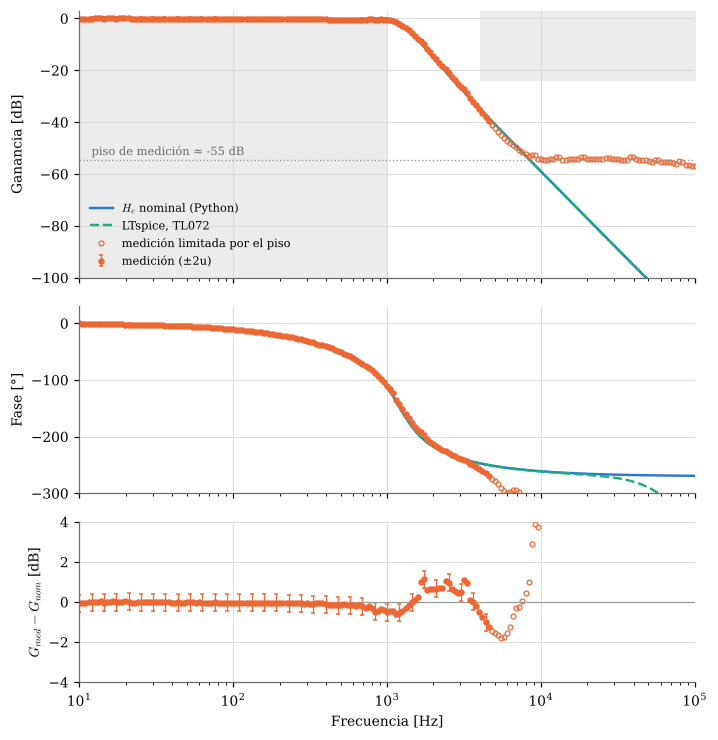

In [8]:
def leer_ltspice_v6_v1():
    """V(6)/V(1) del .raw AC con el modelo TL072 (si existe)."""
    try:
        from spicelib import RawRead
    except ImportError:
        return None
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / 'filtro_TL072_ac.raw'
        if p.exists():
            raw = RawRead(str(p))
            fr = np.real(raw.get_trace('frequency').get_wave())
            return np.abs(fr), raw.get_trace('V(6)').get_wave() / raw.get_trace('V(1)').get_wave()
    return None

lt = leer_ltspice_v6_v1()
fz = np.geomspace(10, 1e5, 3000)
Hz_ = H_modelo(fz, WR_N, W0_N, Q_N)

def marcar(ax, x, y, yerr, etiqueta=True):
    ax.errorbar(x[valido], y[valido], yerr=yerr, fmt='o', ms=3.2, color=NARANJA, ecolor=NARANJA, elinewidth=0.8, capsize=1.5, errorevery=4,
                label='medición (±2u)' if etiqueta else None)
    ax.plot(x[~valido], y[~valido], 'o', ms=3.2, mfc='none', color=NARANJA, mew=0.8,
            label='medición limitada por el piso' if etiqueta else None)

if HAY_DATOS:
    fig, axs = plt.subplots(3, 1, figsize=(6.6, 6.8), sharex=True, gridspec_kw={'height_ratios': [2, 1.4, 1.2]})
    axs[0].semilogx(fz, 20 * np.log10(np.abs(Hz_)), color=AZUL, label='$H_c$ nominal (Python)')
    if lt:
        axs[0].semilogx(lt[0], 20 * np.log10(np.abs(lt[1])), color=VERDE, ls='--', label='LTspice, TL072')
    marcar(axs[0], f_m, G_m, 2 * uG)
    if np.isfinite(PISO):
        axs[0].axhline(PISO, color=GRIS, lw=0.9, ls=':'); axs[0].text(12, PISO + 2, f'piso de medición ≈ {PISO:.0f} dB', fontsize=7.5, color='#6b6b67')
    axs[0].fill_between([1, PL['fp']], -120, -PL['Ap'], color=GRIS, alpha=0.18, lw=0)
    axs[0].fill_between([PL['fs'], 1e6], -PL['As'], 5, color=GRIS, alpha=0.18, lw=0)
    axs[0].set(ylim=(-100, 3), ylabel='Ganancia [dB]'); axs[0].legend(fontsize=7.5, loc='lower left')
    axs[1].semilogx(fz, np.degrees(np.unwrap(np.angle(Hz_))), color=AZUL)
    if lt:
        axs[1].semilogx(lt[0], np.degrees(np.unwrap(np.angle(lt[1]))), color=VERDE, ls='--')
    marcar(axs[1], f_m, F_m, 2 * uF, etiqueta=False)
    axs[1].set(ylabel='Fase [°]', ylim=(-300, 30))
    dG = G_m - 20 * np.log10(np.abs(H_modelo(f_m, WR_N, W0_N, Q_N)))
    marcar(axs[2], f_m, dG, 2 * uG, etiqueta=False)
    axs[2].axhline(0, color=GRIS, lw=0.8)
    axs[2].set(xlim=(10, 1e5), ylim=(-4, 4), xlabel='Frecuencia [Hz]', ylabel='$G_{med} - G_{nom}$ [dB]')
    fig.tight_layout(); guardar(fig, 'fig_mediciones_bode'); plt.show()

## 5. Parámetros característicos y ajuste del modelo
**Directos (interpolando la medición válida):** $A_{p,\max}$ en la banda de paso (referida a la ganancia en baja frecuencia), $|H|$ en 1 kHz y en
4 kHz, frecuencia de −3 dB.

**Ajuste:** se estiman $f_r$, $f_0$, $Q$ y una ganancia $K$ minimizando los residuos de ganancia (dB) de los puntos válidos (mínimos cuadrados no
lineales). La incertidumbre de los parámetros sale de la matriz de covarianza $(J^TJ)^{-1}$ escalada por el $\chi^2$ reducido cuando éste es mayor
que 1. Con la segunda medición (puntas ×10 y calibración de canales) **se ajustan ganancia y fase**: la fase es la que fija $f_r$, que con la
ganancia sola queda fuertemente correlacionado con $Q$.

Ajuste con corte −20 dB: [8.0444580e+02 1.2362972e+03 1.4055000e+00 9.9730000e-01] | −40 dB (sesgado, no se usa): [7.2968680e+02 1.2540654e+03 1.5284000e+00 1.0003000e+00] -> u(banda) = [1.80303e+01 4.74160e+00 2.89000e-02 1.30000e-03]
chi^2 reducido (ganancia) = 0.53;  residuo rms: ganancia 0.317 dB, fase (verificación) 3.15°
Con la fase incluida en el ajuste: chi^2 reducido = 0.53, parámetros [7.8641550e+02 1.2410388e+03 1.4344000e+00 9.9860000e-01]


,parámetro,nominal,ajustado,u (k=1),desvío %
0,f_r [Hz],774.0999,786.4155,19.1232,1.5910
1,f_0 [Hz],1201.0788,1241.0388,5.6236,3.3270
2,Q,1.5525,1.4344,0.0302,-7.6109
3,K,1.0000,0.9986,0.0028,-0.1410


{'G_baja': -0.0092, 'Ap_max_med': 0.5908, 'G1k_med': -0.6, 'G4k_med': -35.2245, 'f3dB_med': 1278.8443, 'fr_corte40': np.float64(729.6868), 'f0_corte40': np.float64(1254.0654), 'Q_corte40': np.float64(1.5284), 'chi2r_G': 0.2653, 'chi2r_GF': 0.529, 'chi2r': np.float64(0.529), 'fr_aj': np.float64(786.4155), 'f0_aj': np.float64(1241.0388), 'Q_aj': np.float64(1.4344), 'K_aj': np.float64(0.9986), 'u_fr': np.float64(19.1232), 'u_f0': np.float64(5.6236), 'u_Q': np.float64(0.0302), 'u_K': np.float64(0.0028), 'rms_res_G': 0.3174, 'rms_res_F': 3.1462, 'n_validos': 134, 'f_max_valido': 4570.88, 'piso': -54.66, 'f_max_ajuste': 3311.31, 'corte_dB': 30.0, 'Ap_max_aj': 0.5986, 'A4k_aj': 33.9866, 'f3dB_aj': 1295.9854, 'Ap_max_nom': 0.2984, 'A4k_nom': 34.6957, 'f3dB_nom': 1304.0856, 'A4k_med': 35.2153, 'cumple': True}


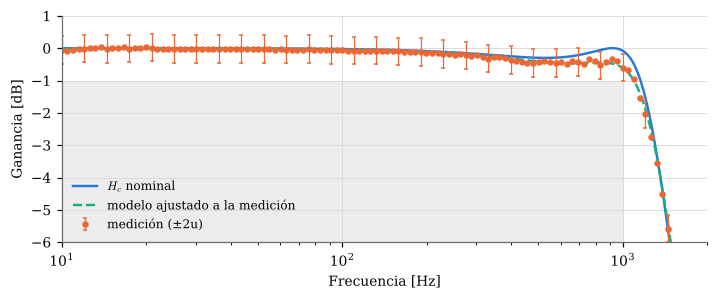

In [9]:
RES_MED = {}
if HAY_DATOS:
    fv, Gv, Fv = f_m[valido], G_m[valido], F_m[valido]
    def interp_db(fq):
        return float(np.interp(np.log(fq), np.log(fv), Gv)) if fv.min() <= fq <= fv.max() else np.nan
    G_ref = float(np.mean(Gv[fv <= 30])) if (fv <= 30).sum() else float(Gv[0])
    paso = fv <= PL['fp']
    RES_MED['G_baja'] = G_ref
    RES_MED['Ap_max_med'] = float(G_ref - Gv[paso].min())
    RES_MED['G1k_med'] = interp_db(1000.0)
    RES_MED['G4k_med'] = interp_db(4000.0)
    cruza = np.where(np.diff(np.sign(Gv - (G_ref - 3.0103))) != 0)[0]
    if len(cruza):
        i = cruza[0]
        RES_MED['f3dB_med'] = float(np.exp(np.interp(G_ref - 3.0103, [Gv[i + 1], Gv[i]], [np.log(fv[i + 1]), np.log(fv[i])])))

    AJUSTAR_FASE = bool(SEGUNDA)       # con puntas ×10 y calibración la fase es confiable y se incluye en el ajuste
    # Banda del ajuste: puntos con la salida a no más de CORTE_dB por debajo de la ganancia de continua. Con la salida más chica la fase medida
    # se vuelve ruidosa y sesga el ajuste (ver la incertidumbre sistemática por elección de banda, abajo).
    CORTE_dB = 30.0 if SEGUNDA else 60.0
    def residuos(p, con_fase=AJUSTAR_FASE, corte=None):
        corte = CORTE_dB if corte is None else corte
        mk = Gv >= G_ref - corte
        fr, f0, Q, K = p
        Hp = H_modelo(fv[mk], 2 * np.pi * fr, 2 * np.pi * f0, Q, K)
        rG = (20 * np.log10(np.abs(Hp)) - Gv[mk]) / uG
        return np.concatenate([rG, (np.degrees(np.unwrap(np.angle(Hp))) - Fv[mk]) / uF]) if con_fase else rG
    p0 = [WR_N / 2 / np.pi, W0_N / 2 / np.pi, Q_N, 1.0]
    aj = optimize.least_squares(residuos, p0, x_scale=[100, 100, 0.1, 0.01])
    # Incertidumbre sistemática por la elección de la banda: diferencia con el ajuste cortado a −20 dB (también con buena relación señal/ruido).
    # Con corte a −40 dB entran puntos con la salida cerca del piso, cuya fase ruidosa sesga el ajuste: se informa pero no se usa.
    if SEGUNDA:
        alt_ = {c_: optimize.least_squares(lambda p: residuos(p, corte=c_), p0, x_scale=[100, 100, 0.1, 0.01]).x for c_ in (20.0, 40.0)}
        U_BANDA = np.abs(alt_[20.0] - aj.x)
        RES_MED.update({'fr_corte40': alt_[40.0][0], 'f0_corte40': alt_[40.0][1], 'Q_corte40': alt_[40.0][2]})
        print('Ajuste con corte −20 dB:', np.round(alt_[20.0], 4), '| −40 dB (sesgado, no se usa):', np.round(alt_[40.0], 4),
              '-> u(banda) =', np.round(U_BANDA, 4))
    else:
        U_BANDA = np.zeros(4)
    J = aj.jac; dof = max(len(aj.fun) - len(p0), 1); chi2r = np.sum(aj.fun**2) / dof
    cov = np.linalg.pinv(J.T @ J) * max(chi2r, 1.0)
    up_est = np.sqrt(np.diag(cov))
    up = np.sqrt(up_est**2 + U_BANDA**2)          # estadística + sistemática por banda
    nom = [WR_N / 2 / np.pi, W0_N / 2 / np.pi, Q_N, 1.0]
    ajuste = pd.DataFrame({'parámetro': ['f_r [Hz]', 'f_0 [Hz]', 'Q', 'K'], 'nominal': nom, 'ajustado': aj.x, 'u (k=1)': up})
    ajuste['desvío %'] = 100 * (ajuste['ajustado'] / ajuste['nominal'] - 1)
    mfit = Gv >= G_ref - CORTE_dB
    res_G = (Gv - 20 * np.log10(np.abs(H_modelo(fv, 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2], aj.x[3]))))
    aj_g = aj if not AJUSTAR_FASE else optimize.least_squares(lambda p: residuos(p, False), p0, x_scale=[100, 100, 0.1, 0.01])
    RES_MED['chi2r_G'] = float(np.sum(aj_g.fun**2) / max(len(aj_g.fun) - 4, 1))
    res_F = Fv - np.degrees(np.unwrap(np.angle(H_modelo(fv, 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2], aj.x[3]))))
    aj_gf = optimize.least_squares(lambda p: residuos(p, True), p0, x_scale=[100, 100, 0.1, 0.01])
    RES_MED['chi2r_GF'] = float(np.sum(aj_gf.fun**2) / max(len(aj_gf.fun) - 4, 1))
    RES_MED.update({'chi2r': chi2r, 'fr_aj': aj.x[0], 'f0_aj': aj.x[1], 'Q_aj': aj.x[2], 'K_aj': aj.x[3],
                    'u_fr': up[0], 'u_f0': up[1], 'u_Q': up[2], 'u_K': up[3],
                    'rms_res_G': float(np.sqrt(np.mean(res_G**2))), 'rms_res_F': float(np.sqrt(np.mean(res_F**2))),
                    'n_validos': int(valido.sum()), 'f_max_valido': float(fv.max()), 'piso': PISO,
                    'f_max_ajuste': float(fv[mfit].max()), 'corte_dB': CORTE_dB})
    print(f'chi^2 reducido (ganancia) = {chi2r:.2f};  residuo rms: ganancia {RES_MED["rms_res_G"]:.3f} dB, fase (verificación) {RES_MED["rms_res_F"]:.2f}°')
    print(f'Con la fase incluida en el ajuste: chi^2 reducido = {RES_MED["chi2r_GF"]:.2f}, parámetros {np.round(aj_gf.x, 4)}')
    display(ajuste.round(4))
    fq = np.append(np.geomspace(1, PL['fp'], 4000), PL['fp'])
    Haj = H_modelo(fq, 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2], 1.0)
    RES_MED['Ap_max_aj'] = float(-(20 * np.log10(np.abs(Haj))).min())
    RES_MED['A4k_aj'] = float(-20 * np.log10(abs(H_modelo(PL['fs'], 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2], 1.0))))
    RES_MED['f3dB_aj'] = float(optimize.brentq(lambda x: abs(H_modelo(x, 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2])) - 10**(-3.0103 / 20), 500, 5000))
    RES_MED['Ap_max_nom'] = float(-(20 * np.log10(np.abs(H_modelo(fq, WR_N, W0_N, Q_N)))).min())
    RES_MED['A4k_nom'] = float(-20 * np.log10(abs(H_modelo(PL['fs'], WR_N, W0_N, Q_N))))
    RES_MED['f3dB_nom'] = float(optimize.brentq(lambda x: abs(H_modelo(x, WR_N, W0_N, Q_N)) - 10**(-3.0103 / 20), 500, 5000))
    RES_MED['A4k_med'] = float(G_ref - RES_MED['G4k_med'])
    RES_MED['cumple'] = bool((RES_MED['Ap_max_med'] <= PL['Ap']) and (-RES_MED['G4k_med'] >= PL['As']))
    print({k_: (round(v, 4) if isinstance(v, float) else v) for k_, v in RES_MED.items()})

    # Detalle de la banda de paso con el modelo ajustado
    fig, ax = plt.subplots(figsize=(6.6, 2.8))
    fd = np.geomspace(10, 2000, 1500)
    ax.semilogx(fd, 20 * np.log10(np.abs(H_modelo(fd, WR_N, W0_N, Q_N))), color=AZUL, label='$H_c$ nominal')
    ax.semilogx(fd, 20 * np.log10(np.abs(H_modelo(fd, 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2], aj.x[3]))), color=VERDE, ls='--',
                label='modelo ajustado a la medición')
    mm = f_m <= 2000
    ax.errorbar(f_m[mm], G_m[mm], yerr=2 * uG, fmt='o', ms=3.2, color=NARANJA, elinewidth=0.8, capsize=1.5, errorevery=4, label='medición (±2u)')
    ax.fill_between([1, PL['fp']], -10, -PL['Ap'], color=GRIS, alpha=0.18, lw=0)
    ax.set(xlim=(10, 2000), ylim=(-6, 1), xlabel='Frecuencia [Hz]', ylabel='Ganancia [dB]'); ax.legend(fontsize=8, loc='lower left')
    fig.tight_layout(); guardar(fig, 'fig_mediciones_paso'); plt.show()

### 5.1 Verificación con la fase medida
La fase de un filtro de fase mínima como éste decrece monótonamente con la frecuencia. Los puntos válidos donde la fase medida (desenrollada)
**aumenta** respecto del anterior delatan errores del instrumento. Se grafica el residuo de fase respecto del modelo ajustado con la ganancia.

Puntos válidos con fase no monótona (salto > +0,5°): 0 -> []


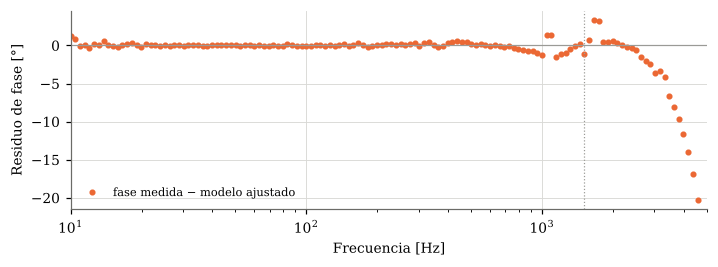

Residuo rms de fase hasta 1 kHz: 0.30°; en todo el rango válido: 3.15°


In [10]:
if HAY_DATOS:
    no_monot = np.where(np.diff(Fv) > 0.5)[0] + 1
    RES_MED['n_no_monot'] = int(len(no_monot))
    print(f'Puntos válidos con fase no monótona (salto > +0,5°): {len(no_monot)} ->', np.round(fv[no_monot], 0))
    fig, ax = plt.subplots(figsize=(6.6, 2.5))
    ax.semilogx(fv, res_F, 'o', ms=3, color=NARANJA, label='fase medida − modelo ajustado')
    if len(no_monot): ax.semilogx(fv[no_monot], res_F[no_monot], 'x', ms=6, color='#3a3a38', label='fase no monótona (error del instrumento)')
    ax.axhline(0, color=GRIS, lw=0.8); ax.axvline(fv[np.argmin(np.abs(Fv + 180))], color=GRIS, ls=':', lw=0.8)
    ax.set(xlabel='Frecuencia [Hz]', ylabel='Residuo de fase [°]', xlim=(10, fv.max() * 1.1)); ax.legend(fontsize=7.5, loc='lower left')
    fig.tight_layout(); guardar(fig, 'fig_mediciones_fase_residuo'); plt.show()
    m500 = fv <= 1000
    RES_MED['rms_res_F_paso'] = float(np.sqrt(np.mean(res_F[m500]**2)))
    print(f'Residuo rms de fase hasta 1 kHz: {RES_MED["rms_res_F_paso"]:.2f}°; en todo el rango válido: {RES_MED["rms_res_F"]:.2f}°')

COMPARA = []

## 6. Estimación indirecta de los capacitores
Sin LCR, los valores reales de $C_0$, $C_1$ y $C_2$ se estiman invirtiendo las expresiones del circuito con los parámetros ajustados y las resistencias
medidas (o nominales si no se midieron): $C_0 = 1/(\omega_r R_0)$; de $Q$ y $\omega_0$:
$\dfrac{C_1}{C_2} = \dfrac{Q^2(R_1+R_2)^2}{R_1R_2}$ y $C_1C_2 = \dfrac{1}{\omega_0^2R_1R_2}$. La incertidumbre se propaga por Monte Carlo a partir de la
covarianza del ajuste y de la tolerancia de las resistencias (1 % uniforme si no se midieron).

In [11]:
def r_medida(ref):
    """Resistencia medida: acepta el total del par ('R0') o cada resistencia ('R0a', 'R0b'). Si no hay medición, usa la nominal."""
    rm = META.get('resistencias_medidas_ohm', {}) or {}
    if isinstance(rm.get(ref), (int, float)):
        return float(rm[ref]), True
    a_, b_ = rm.get(ref + 'a'), rm.get(ref + 'b')
    if a_ is None:
        return COMP[ref], False
    return float(a_) + float(b_ or 0.0), True

TOL_R_MEDIDA = (META.get('multimetro', {}) or {}).get('precision_ohm_pct') or 1.0

if HAY_DATOS:
    R0m, m0 = r_medida('R0'); R1m, m1 = r_medida('R1'); R2m, m2 = r_medida('R2')
    def caps(fr, f0, Q, R0_, R1_, R2_):
        wr_, w0_ = 2 * np.pi * fr, 2 * np.pi * f0
        razon = Q**2 * (R1_ + R2_)**2 / (R1_ * R2_); prod = 1 / (w0_**2 * R1_ * R2_)
        return 1 / (wr_ * R0_), np.sqrt(prod * razon), np.sqrt(prod / razon)
    C0e, C1e, C2e = caps(aj.x[0], aj.x[1], aj.x[2], R0m, R1m, R2m)
    rng = np.random.default_rng(11); M = 20000
    mu = rng.multivariate_normal(aj.x[:3], cov[:3, :3] + np.diag(U_BANDA[:3]**2), M)   # estadística + sistemática por banda
    tolR = lambda R_, medida: R_ * (1 + (TOL_R_MEDIDA / 100 if medida else 0.01) * rng.uniform(-1, 1, M))
    mc = np.array(caps(mu[:, 0], mu[:, 1], mu[:, 2], tolR(R0m, m0), tolR(R1m, m1), tolR(R2m, m2)))
    uC = mc.std(axis=1)
    cap = pd.DataFrame({'capacitor': ['C0', 'C1', 'C2'], 'nominal [nF]': [COMP['C0'] * 1e9, COMP['C1'] * 1e9, COMP['C2'] * 1e9],
                        'estimado [nF]': [C0e * 1e9, C1e * 1e9, C2e * 1e9], 'u (k=1) [nF]': uC * 1e9})
    cap['desvío %'] = 100 * (cap['estimado [nF]'] / cap['nominal [nF]'] - 1)
    cap['u desvío (k=1) %'] = 100 * cap['u (k=1) [nF]'] / cap['nominal [nF]']
    print('Resistencias usadas:', {'R0': (R0m, 'medida' if m0 else 'nominal'), 'R1': (R1m, 'medida' if m1 else 'nominal'),
                                  'R2': (R2m, 'medida' if m2 else 'nominal')})
    display(cap.round(3))
    RES_MED.update({'C0_est': C0e, 'C1_est': C1e, 'C2_est': C2e,
                    'dC0': cap['desvío %'][0], 'dC1': cap['desvío %'][1], 'dC2': cap['desvío %'][2],
                    'uC0': cap['u desvío (k=1) %'][0], 'uC1': cap['u desvío (k=1) %'][1], 'uC2': cap['u desvío (k=1) %'][2],
                    'R_medidas': bool(m0 and m1 and m2)})

Resistencias usadas: {'R0': (20290.0, 'medida'), 'R1': (10750.0, 'medida'), 'R2': (7300.0, 'medida')}


,capacitor,nominal [nF],estimado [nF],u (k=1) [nF],desvío %,u desvío (k=1) %
0,C0,10.0,9.974,0.249,-0.256,2.491
1,C1,47.0,42.309,0.919,-9.980,1.955
2,C2,4.7,4.953,0.110,5.391,2.339


**Consistencia con el análisis de sensibilidad.** La variación de $|H(j\omega)|$ en 1 kHz que predicen las sensibilidades de la magnitud (notebook 03)
para los desvíos estimados de los capacitores y los medidos de las resistencias, $\Delta|H|_{\mathrm{dB}} \approx \frac{20}{\ln10}\sum_x S^{|H|}_x\,\Delta x/x$, se compara con la
diferencia medida entre la ganancia en 1 kHz y la nominal.

In [12]:
if HAY_DATOS:
    def gdb(c_, f_):
        return 20 * np.log10(abs(H_modelo(f_, *parametros_de_componentes(c_))))
    pred = 0.0
    desv_R = [(r_, 100 * (r_medida(r_)[0] / COMP[r_] - 1)) for r_ in ('R0', 'R1', 'R2')]
    for nombre_c, d_pct in [('C0', RES_MED['dC0']), ('C1', RES_MED['dC1']), ('C2', RES_MED['dC2'])] + desv_R:
        cp = dict(COMP); cm = dict(COMP); cp[nombre_c] *= 1.001; cm[nombre_c] *= 0.999
        S_ = (gdb(cp, 1000.0) - gdb(cm, 1000.0)) / (20 / np.log(10)) / (np.log(1.001) - np.log(0.999))
        pred += 20 / np.log(10) * S_ * d_pct / 100
        print(f'S^|H|_{nombre_c}(1 kHz) = {S_:+.3f}, desvío {d_pct:+.2f} % -> {20/np.log(10)*S_*d_pct/100:+.3f} dB')
    medido = (RES_MED['G1k_med'] - G_ref) - 20 * np.log10(abs(H_modelo(1000.0, WR_N, W0_N, Q_N)))
    RES_MED['dG1k_pred'] = float(pred); RES_MED['dG1k_med'] = float(medido)
    print(f'Predicción lineal: {pred:+.2f} dB; medido: {medido:+.2f} dB')

S^|H|_C0(1 kHz) = -0.625, desvío -0.26 % -> +0.014 dB
S^|H|_C1(1 kHz) = +0.557, desvío -9.98 % -> -0.483 dB
S^|H|_C2(1 kHz) = -0.196, desvío +5.39 % -> -0.092 dB
S^|H|_R0(1 kHz) = -0.625, desvío -1.31 % -> +0.071 dB
S^|H|_R1(1 kHz) = +0.109, desvío -0.46 % -> -0.004 dB
S^|H|_R2(1 kHz) = +0.252, desvío -0.82 % -> -0.018 dB
Predicción lineal: -0.51 dB; medido: -0.51 dB


### 6.1 ¿Qué habría pasado sin margen de diseño?
Se aplican los **mismos desvíos relativos** (capacitores estimados y resistencias medidas) a una síntesis de $H_t$ (sin margen, $A_p$ = 1 dB, $f_p$ = 1 kHz) con la
misma topología y los mismos capacitores nominales, y se evalúa la plantilla.

In [13]:
if HAY_DATOS:
    from scipy import signal as _sg
    z_, p_, k_ = _sg.cheby1(3, PL['Ap'], 2 * np.pi * PL['fp'], analog=True, output='zpk')
    pr_ = p_[np.abs(p_.imag) < 1e-6 * np.abs(p_)].real[0]; pc_ = p_[p_.imag > 0][0]
    wr_t, w0_t, Q_t = -pr_, abs(pc_), abs(pc_) / (-2 * pc_.real)
    n_ = COMP['C1'] / COMP['C2']
    if 4 * Q_t**2 > n_:
        n_ = 100 / 4.7          # par disponible con n suficiente para el Q de H_t
    q_ = np.sqrt(1 - 4 * Q_t**2 / n_)
    C2t = COMP['C2']; C1t = n_ * C2t; R1t = (1 + q_) / (2 * Q_t * w0_t * C2t); R2t = (1 - q_) / (2 * Q_t * w0_t * C2t); R0t = 1 / (wr_t * COMP['C0'])
    d0, d1, d2 = 1 + RES_MED['dC0'] / 100, 1 + RES_MED['dC1'] / 100, 1 + RES_MED['dC2'] / 100
    e0, e1, e2 = [r_medida(r_)[0] / COMP[r_] for r_ in ('R0', 'R1', 'R2')]
    c_real = {'R0': R0t * e0, 'C0': COMP['C0'] * d0, 'R1': R1t * e1, 'R2': R2t * e2, 'C1': C1t * d1, 'C2': C2t * d2}
    wr_c_, w0_c_, Q_c_ = parametros_de_componentes(c_real)
    fq = np.append(np.geomspace(1, PL['fp'], 4000), PL['fp'])
    RES_MED['Ap_sin_margen'] = float(-(20 * np.log10(np.abs(H_modelo(fq, wr_c_, w0_c_, Q_c_)))).min())
    print(f'Síntesis sin margen con los mismos desvíos de C: A_p,max = {RES_MED["Ap_sin_margen"]:.2f} dB '
          f'(plantilla ≤ 1 dB) frente a {RES_MED["Ap_max_aj"]:.2f} dB del filtro construido (modelo ajustado).')

Síntesis sin margen con los mismos desvíos de C: A_p,max = 1.35 dB (plantilla ≤ 1 dB) frente a 0.60 dB del filtro construido (modelo ajustado).


## 7. Retardo de grupo a partir de la fase medida
$\tau_g \approx -\Delta\varphi/\Delta\omega$ (con $\omega$ en rad/s). Derivar datos con ruido amplifica el ruido, sobre todo en baja frecuencia donde
$\Delta\omega$ es chico; por eso la diferencia se toma entre puntos separados aproximadamente 0,1 década ($\Delta\omega/\omega \approx 26\,\%$), lo que
reduce el ruido a costa de resolución en frecuencia. Se presenta junto con el retardo del modelo nominal y del modelo ajustado.

Diferencias tomadas cada 5 puntos (≈ 0.10 décadas)


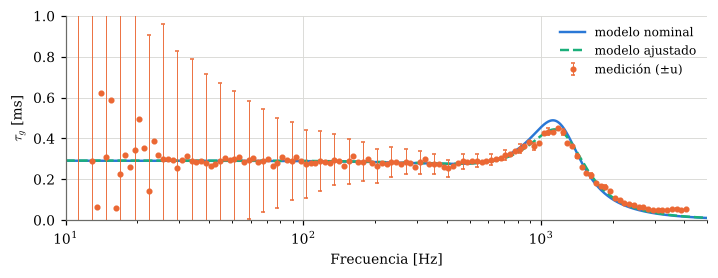

tau_g en baja frecuencia: medido 0.316 ms, nominal 0.290 ms; máximo: medido 0.450 ms, nominal 0.489 ms


In [14]:
def tau_modelo(f, wr, w0, Q):
    w = 2 * np.pi * np.asarray(f, float)
    p = np.roots([1, w0 / Q, w0**2]); tau = wr / (wr**2 + w**2)
    for pk in p:
        tau = tau + (-pk.real) / (pk.real**2 + (w - pk.imag)**2)
    return tau

if HAY_DATOS and valido.sum() > 3:
    fv_, Fv_ = f_m[valido], F_m[valido]
    w_m = 2 * np.pi * fv_
    paso_dec = np.median(np.diff(np.log10(fv_)))
    kk = max(int(round(0.1 / paso_dec)), 1) if paso_dec > 0 else 1
    i_ = np.arange(0, len(fv_) - kk)
    tau_m = -(np.radians(Fv_[i_ + kk]) - np.radians(Fv_[i_])) / (w_m[i_ + kk] - w_m[i_])
    f_mid = np.sqrt(fv_[i_ + kk] * fv_[i_])
    u_tau = np.sqrt(2) * np.radians(uF) / (w_m[i_ + kk] - w_m[i_])
    print(f'Diferencias tomadas cada {kk} puntos (≈ {kk*paso_dec:.2f} décadas)')
    fig, ax = plt.subplots(figsize=(6.6, 2.6))
    ft = np.geomspace(10, 5000, 1000)
    ax.semilogx(ft, 1e3 * tau_modelo(ft, WR_N, W0_N, Q_N), color=AZUL, label='modelo nominal')
    ax.semilogx(ft, 1e3 * tau_modelo(ft, 2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2]), color=VERDE, ls='--', label='modelo ajustado')
    msk = f_mid <= 5000
    ax.errorbar(f_mid[msk], 1e3 * tau_m[msk], yerr=1e3 * u_tau[msk], fmt='o', ms=3, color=NARANJA, elinewidth=0.6, capsize=1.2, errorevery=3,
                label='medición (±u)')
    ax.set(xlabel='Frecuencia [Hz]', ylabel='$\\tau_g$ [ms]', xlim=(10, 5000), ylim=(0, 1.0)); ax.legend(fontsize=8)
    fig.tight_layout(); guardar(fig, 'fig_mediciones_retardo'); plt.show()
    sel_ = (f_mid > 500) & (f_mid < 2000)
    RES_MED['tau_max_med_aprox'] = 1e3 * float(np.max(tau_m[sel_])) if sel_.any() else np.nan          # en ms
    RES_MED['tau_baja_med'] = 1e3 * float(np.mean(tau_m[f_mid < 200])) if (f_mid < 200).any() else np.nan  # en ms
    RES_MED['tau_baja_nom'] = 1e3 * float(tau_modelo(50.0, WR_N, W0_N, Q_N))
    RES_MED['tau_max_nom'] = 1e3 * float(np.max(tau_modelo(np.geomspace(500, 2000, 2000), WR_N, W0_N, Q_N)))
    print(f"tau_g en baja frecuencia: medido {RES_MED['tau_baja_med']:.3f} ms, nominal {RES_MED['tau_baja_nom']:.3f} ms; "
          f"máximo: medido {RES_MED['tau_max_med_aprox']:.3f} ms, nominal {RES_MED['tau_max_nom']:.3f} ms")

## 8. Respuesta al escalón
Se lee `mediciones/nivel3/escalon_cascada.csv` (exportación del osciloscopio: tiempo, CH1 = entrada, CH2 = salida del filtro, CH3 = salida del
ecualizador del Nivel III, que acá no se usa). La salida se normaliza por el salto de la
entrada; se miden sobrepico, tiempo de subida 10–90 % y valor final, y se comparan con la respuesta de $H_c$ nominal y del modelo ajustado.

Escalón: mediciones/nivel3/escalon_cascada.csv
Resolución vertical (1 LSB) de la salida: 43.5 mV = 2.2 % del escalón -> u(sobrepico) ≈ 1.3 puntos
{'sobrepico_med': np.float64(7.871), 'u_sobrepico': np.float64(1.258), 'lsb_mV': 43.515, 'tr_med_us': np.float64(306.8), 'ganancia_cc_med': np.float64(1.004), 'escalon_V': np.float64(1.997), 'sobrepico_nom': np.float64(9.784), 'tr_nom_us': np.float64(300.069), 'sobrepico_aj': np.float64(7.656), 'tr_aj_us': np.float64(302.57)}


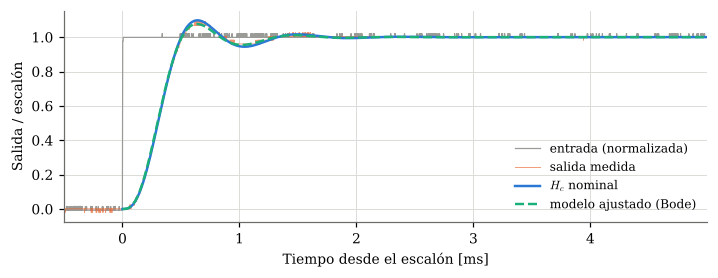

In [15]:
ESC = None
ARCH_ESC = MED3 / 'escalon_cascada.csv' if (MED3 / 'escalon_cascada.csv').exists() else None
if ARCH_ESC is not None:
    e = pd.read_csv(ARCH_ESC)
    if ARCH_ESC.name.startswith('escalon_cascada'):      # Time, CH1 = entrada, CH2 = salida del filtro, CH3 = salida del ecualizador
        e = e.iloc[:, :3]; e.columns = ['t', 'vi', 'vo']
    else:                                                 # formato de dos canales: Time, CH1 = salida, CH2 = entrada
        e.columns = ['t', 'vo', 'vi'] + list(e.columns[3:])
    print('Escalón:', ARCH_ESC.relative_to(ROOT))
    t_, vo_, vi_ = e['t'].to_numpy(float), e['vo'].to_numpy(float), e['vi'].to_numpy(float)
    vi0, vi1 = vi_[t_ < -0.2e-3].mean(), vi_[t_ > 0.5e-3].mean()
    t0 = t_[np.argmax(vi_ > (vi0 + vi1) / 2)]
    vo0 = vo_[t_ < t0 - 0.2e-3].mean()
    vo_fin = vo_[(t_ - t0 > 1.8e-3) & (t_ - t0 < 2.4e-3)].mean()
    # media móvil de 20 µs (el pico dura cientos de µs): reduce el ruido y la cuantización sin deformar el máximo
    paso_t = np.median(np.diff(t_)); nmed = max(int(round(20e-6 / paso_t)), 1)
    lsb = float(np.min(np.diff(np.unique(np.round(vo_, 9)))))
    vo_s = np.convolve(vo_, np.ones(nmed) / nmed, mode='same')
    y = (vo_s - vo0) / (vi1 - vi0); yf = (vo_fin - vo0) / (vi1 - vi0)
    tt = t_ - t0
    post = tt > 0
    sobre = 100 * (y[post].max() - yf) / yf
    t10 = tt[post][np.argmax(y[post] >= 0.1 * yf)]; t90 = tt[post][np.argmax(y[post] >= 0.9 * yf)]
    def escalon_modelo(wr, w0, Q, T):
        sys_ = signal.lti([wr * w0**2], np.polymul([1, wr], [1, w0 / Q, w0**2]))
        return signal.step(sys_, T=T)
    Tm = np.linspace(0, tt.max(), 4000)
    _, y_nom = escalon_modelo(WR_N, W0_N, Q_N, Tm)
    sobre_nom = 100 * (y_nom.max() - 1)
    tr_nom = Tm[np.argmax(y_nom >= 0.9)] - Tm[np.argmax(y_nom >= 0.1)]
    u_sobre = 100 * lsb / (np.sqrt(3) * (vi1 - vi0))
    print(f'Resolución vertical (1 LSB) de la salida: {1e3*lsb:.1f} mV = {100*lsb/(vi1-vi0):.1f} % del escalón -> u(sobrepico) ≈ {u_sobre:.1f} puntos')
    ESC = {'sobrepico_med': sobre, 'u_sobrepico': u_sobre, 'lsb_mV': 1e3 * lsb, 'tr_med_us': 1e6 * (t90 - t10), 'ganancia_cc_med': yf, 'escalon_V': vi1 - vi0,
           'sobrepico_nom': sobre_nom, 'tr_nom_us': 1e6 * tr_nom}
    if HAY_DATOS:
        _, y_aj = escalon_modelo(2 * np.pi * aj.x[0], 2 * np.pi * aj.x[1], aj.x[2], Tm)
        ESC.update({'sobrepico_aj': 100 * (y_aj.max() - 1), 'tr_aj_us': 1e6 * (Tm[np.argmax(y_aj >= 0.9)] - Tm[np.argmax(y_aj >= 0.1)])})
    print({k_: round(v, 3) for k_, v in ESC.items()})
    fig, ax = plt.subplots(figsize=(6.6, 2.6))
    ax.plot(1e3 * tt, (vi_ - vi0) / (vi1 - vi0), color=GRIS, lw=0.8, label='entrada (normalizada)')
    ax.plot(1e3 * tt, (vo_ - vo0) / (vi1 - vi0), color=NARANJA, lw=0.6, alpha=0.7, label='salida medida')
    ax.plot(1e3 * Tm, y_nom, color=AZUL, label='$H_c$ nominal')
    if HAY_DATOS:
        ax.plot(1e3 * Tm, y_aj, color=VERDE, ls='--', label='modelo ajustado (Bode)')
    ax.set(xlim=(-0.5, tt.max() * 1e3), xlabel='Tiempo desde el escalón [ms]', ylabel='Salida / escalón')
    ax.legend(fontsize=8, loc='lower right')
    fig.tight_layout(); guardar(fig, 'fig_mediciones_escalon'); plt.show()
    RES_MED.update({k_: v for k_, v in ESC.items()})

## 9. Exportación para el informe

In [16]:
if HAY_DATOS:
    filas = [r'\begin{tabular}{@{}lcccc@{}}', r'\toprule', r'Parámetro & Nominal & Ajustado & $u$ ($k=1$) & Desvío [\%] \\', r'\midrule']
    etiq = {'f_r [Hz]': r'$f_r$ [Hz]', 'f_0 [Hz]': r'$f_0$ [Hz]', 'Q': '$Q$', 'K': r'$K$ (ganancia)'}
    for _, r in ajuste.iterrows():
        nd = 4 if r['parámetro'] in ('Q', 'K') else 1
        filas.append(f"{etiq[r['parámetro']]} & {num(r['nominal'], nd)} & {num(r['ajustado'], nd)} & {num(r['u (k=1)'], nd)} & {num(r['desvío %'], 2)} \\\\")
    filas += [r'\bottomrule', r'\end{tabular}']
    (RES / 'tab_ajuste_medicion.tex').write_text('\n'.join(filas), encoding='utf-8')

    filas = [r'\begin{tabular}{@{}lccc@{}}', r'\toprule', r'Magnitud & Plantilla & Nominal ($H_c$) & Medición \\', r'\midrule',
             f"$A_{{p,\\max}}$ en $f \\le \\qty{{1}}{{\\kilo\\hertz}}$ [dB] & $\\le 1$ & {num(RES_MED['Ap_max_nom'], 2)} & {num(RES_MED['Ap_max_med'], 2)} \\\\",
             f"$A(\\qty{{1}}{{\\kilo\\hertz}})$ [dB] & $\\le 1$ & {num(-20*np.log10(abs(H_modelo(1000, WR_N, W0_N, Q_N))), 2)} & {num(G_ref - RES_MED['G1k_med'], 2)} \\\\",
             f"$A(\\qty{{4}}{{\\kilo\\hertz}})$ [dB] & $\\ge 24$ & {num(RES_MED['A4k_nom'], 1)} & {num(G_ref - RES_MED['G4k_med'], 1)} \\\\",
             f"Frecuencia de \\qty{{-3}}{{\\decibel}} [Hz] & --- & {num(RES_MED['f3dB_nom'], 0)} & {num(RES_MED.get('f3dB_med', np.nan), 0)} \\\\"]
    if ESC:
        filas += [f"Sobrepico al escalón [\\%] & --- & {num(ESC['sobrepico_nom'], 1)} & {num(ESC['sobrepico_med'], 1)} $\\pm$ {num(ESC['u_sobrepico'], 1)} \\\\",
                  f"Tiempo de subida 10--90\\,\\% [\\si{{\\micro\\second}}] & --- & {num(ESC['tr_nom_us'], 0)} & {num(ESC['tr_med_us'], 0)} \\\\"]
    filas += [r'\bottomrule', r'\end{tabular}']
    (RES / 'tab_parametros_medicion.tex').write_text('\n'.join(filas), encoding='utf-8')

    filas = [r'\begin{tabular}{@{}lcccc@{}}', r'\toprule', r'Capacitor & Nominal [nF] & Estimado [nF] & Desvío [\%] & $u$ desvío ($k=1$) [\%] \\', r'\midrule']
    for _, r in cap.iterrows():
        filas.append(f"${r.capacitor[0]}_{r.capacitor[1]}$ & {num(r['nominal [nF]'], 2)} & {num(r['estimado [nF]'], 2)} & {num(r['desvío %'], 1)} & "
                     f"{num(r['u desvío (k=1) %'], 1)} \\\\")
    filas += [r'\bottomrule', r'\end{tabular}']
    (RES / 'tab_capacitores_estimados.tex').write_text('\n'.join(filas), encoding='utf-8')

    pd.DataFrame({'frecuencia_Hz': f_m, 'ganancia_dB': G_m, 'fase_medida_grados': F_raw, 'fase_desenrollada_grados': F_m,
                  'valido': valido}).to_csv(RES / 'mediciones_procesadas.csv', index=False)
    NOMBRES = {'G_baja': 'GBaja', 'Ap_max_med': 'ApMaxMed', 'G1k_med': 'GunokMed', 'G4k_med': 'GcuatrokMed', 'f3dB_med': 'FtresdBMed',
               'chi2r': 'ChiCuadRed', 'fr_aj': 'FrAj', 'f0_aj': 'FoAj', 'Q_aj': 'QAj', 'K_aj': 'KAj', 'u_fr': 'UFr', 'u_f0': 'UFo',
               'u_Q': 'UQ', 'u_K': 'UK', 'rms_res_G': 'RmsResG', 'rms_res_F': 'RmsResF', 'n_validos': 'NValidos',
               'f_max_valido': 'FMaxValido', 'piso': 'Piso', 'Ap_max_aj': 'ApMaxAj', 'A4k_aj': 'AcuatrokAj', 'f3dB_aj': 'FtresdBAj',
               'Ap_max_nom': 'ApMaxNom', 'A4k_nom': 'AcuatrokNom', 'f3dB_nom': 'FtresdBNom',
               'C0_est': 'CceroEst', 'C1_est': 'CunoEst', 'C2_est': 'CdosEst', 'dC0': 'DCcero', 'dC1': 'DCuno', 'dC2': 'DCdos',
               'uC0': 'UCcero', 'uC1': 'UCuno', 'uC2': 'UCdos', 'tau_max_med_aprox': 'TauMaxMed',
               'sobrepico_med': 'SobrepicoMed', 'tr_med_us': 'TrMed', 'ganancia_cc_med': 'GananciaCCMed', 'escalon_V': 'EscalonV',
               'sobrepico_nom': 'SobrepicoNom', 'tr_nom_us': 'TrNom', 'sobrepico_aj': 'SobrepicoAj', 'tr_aj_us': 'TrAj',
               'u_sobrepico': 'USobrepico', 'lsb_mV': 'LsbmV', 'chi2r_GF': 'ChiCuadRedGF', 'n_no_monot': 'NNoMonot',
               'rms_res_F_paso': 'RmsResFPaso', 'Ap_sin_margen': 'ApSinMargen',
               'tau_baja_med': 'TauBajaMed', 'tau_baja_nom': 'TauBajaNom', 'tau_max_nom': 'TauMaxNom',
               'dG1k_pred': 'DGunokPred', 'dG1k_med': 'DGunokMed', 'A4k_med': 'AcuatrokMed', 'chi2r_G': 'ChiCuadRedG',
               'dG_mediciones_max': 'DGMediciones', 'dF_mediciones_max': 'DFMediciones', 'fr_primera': 'FrPrimera', 'f_max_ajuste': 'FMaxAjuste', 'corte_dB': 'CortedB', 'fr_corte40': 'FrCorteCuarenta', 'Q_corte40': 'QCorteCuarenta',
               'f0_primera': 'FoPrimera', 'Q_primera': 'QPrimera'}
    macros = ['% Generado automáticamente por notebooks/04_Mediciones.ipynb — no editar a mano']
    for k_, v in RES_MED.items():
        if k_ in NOMBRES and isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) and np.isfinite(v):
            v_out = v * 1e9 if k_.endswith('_est') else v
            macros.append(f'\\newcommand{{\\m{NOMBRES[k_]}}}{{{float(v_out):.6g}}}')
    if HAY_DATOS:
        for ref_ in ('R0', 'R1', 'R2'):
            rv, med = r_medida(ref_)
            if med:
                macros.append(f'\\newcommand{{\\mR{ {"R0": "cero", "R1": "uno", "R2": "dos"}[ref_] }Med}}{{{rv/1e3:.4g}}}'.replace(' ', ''))
                macros.append(f'\\newcommand{{\\mDR{ {"R0": "cero", "R1": "uno", "R2": "dos"}[ref_] }}}{{{100*(rv/COMP[ref_]-1):.3g}}}'.replace(' ', ''))
        if META.get('offset_salida_mV') is not None:
            macros.append(f"\\newcommand{{\\mOffset}}{{{META['offset_salida_mV']}}}")
        if (META.get('fuente', {}) or {}).get('tension_V'):
            macros.append(f"\\newcommand{{\\mVcc}}{{{abs(META['fuente']['tension_V'][0])}}}")
        macros.append(f'\\newcommand{{\\mTolRMed}}{{{TOL_R_MEDIDA}}}')
        macros.append(f"\\newcommand{{\\mRMedidas}}{{{'1' if RES_MED.get('R_medidas') else '0'}}}")
    macros.append(f"\\newcommand{{\\mSegunda}}{{{int(bool(SEGUNDA))}}}")
    TIMES_ = r'$\times$'
    if len(COMPARA):
        filas_c = [r'\begin{tabular}{@{}llcccc@{}}', r'\toprule', r'Medición & Ajuste con & $f_r$ [Hz] & $f_0$ [Hz] & $Q$ & $\chi^2_\nu$ \\', r'\midrule']
        for _, r in COMPARA.iterrows():
            punt = r['puntas'].replace('×', TIMES_)
            filas_c.append(f"{r['medición'].capitalize()} (puntas {punt}) & {r['criterio']} & {num(r['fr'], 0)} $\\pm$ {num(r['u_fr'], 0)} & "
                           f"{num(r['f0'], 0)} $\\pm$ {num(r['u_f0'], 0)} & {num(r['Q'], 3)} $\\pm$ {num(r['u_Q'], 3)} & {num(r['chi2r'], 2)} \\\\")
        filas_c += [r'\bottomrule', r'\end{tabular}']
        (RES / 'tab_comparacion_mediciones.tex').write_text('\n'.join(filas_c) + '\n', encoding='utf-8')
    macros += [f'\\newcommand{{\\mUG}}{{{uG:.3g}}}', f'\\newcommand{{\\mUF}}{{{uF:.3g}}}', f'\\newcommand{{\\mNfrec}}{{{len(f_m)}}}']
    (RES / 'valores_nb04.tex').write_text('\n'.join(macros) + '\n', encoding='utf-8')
    print('\n'.join(macros))
else:
    print('Sin mediciones: no se exportan resultados experimentales.')

% Generado automáticamente por notebooks/04_Mediciones.ipynb — no editar a mano
\newcommand{\mGBaja}{-0.00916667}
\newcommand{\mApMaxMed}{0.590833}
\newcommand{\mGunokMed}{-0.6}
\newcommand{\mGcuatrokMed}{-35.2245}
\newcommand{\mFtresdBMed}{1278.84}
\newcommand{\mFrCorteCuarenta}{729.687}
\newcommand{\mQCorteCuarenta}{1.52839}
\newcommand{\mChiCuadRedG}{0.265297}
\newcommand{\mChiCuadRedGF}{0.529049}
\newcommand{\mChiCuadRed}{0.529049}
\newcommand{\mFrAj}{786.416}
\newcommand{\mFoAj}{1241.04}
\newcommand{\mQAj}{1.43435}
\newcommand{\mKAj}{0.99859}
\newcommand{\mUFr}{19.1232}
\newcommand{\mUFo}{5.62362}
\newcommand{\mUQ}{0.0301964}
\newcommand{\mUK}{0.00279482}
\newcommand{\mRmsResG}{0.317401}
\newcommand{\mRmsResF}{3.14618}
\newcommand{\mNValidos}{134}
\newcommand{\mFMaxValido}{4570.88}
\newcommand{\mPiso}{-54.66}
\newcommand{\mFMaxAjuste}{3311.31}
\newcommand{\mCortedB}{30}
\newcommand{\mApMaxAj}{0.598572}
\newcommand{\mAcuatrokAj}{33.9866}
\newcommand{\mFtresdBAj}{1295.99}
\newcomman